<a href="https://colab.research.google.com/github/madhukshara09/Codomax-Data-Science-Intern/blob/main/final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
# 1. Clone the MarketSphere repository into Google Colab
!git clone https://github.com/madhukshara09/MarketSphere.git
%cd MarketSphere

# 2. List all files and datasets inside the repository
import os
import glob

print("Repository Contents:")
for root, dirs, files in os.walk("."):
    if ".git" in root:
        continue
    for f in files:
        print(" -", os.path.join(root, f))

# Locate CSV/Excel files automatically
data_files = glob.glob("**/*.csv", recursive=True) + glob.glob("**/*.xlsx", recursive=True)
print("\nDetected Data Files:", data_files)

fatal: destination path 'MarketSphere' already exists and is not an empty directory.
/content/MarketSphere/MarketSphere
Repository Contents:
 - ./bun.lock
 - ./package.json
 - ./.prettierrc
 - ./bunfig.toml
 - ./.gitignore
 - ./package-lock.json
 - ./.prettierignore
 - ./eslint.config.js
 - ./README.md
 - ./components.json
 - ./AGENTS.md
 - ./vite.config.ts
 - ./tsconfig.json
 - ./MarketSphereAI/README.md
 - ./MarketSphereAI/app.py
 - ./MarketSphereAI/requirements.txt
 - ./MarketSphereAI/data/__init__.py
 - ./MarketSphereAI/data/customers.csv
 - ./MarketSphereAI/data/generate_mock_data.py
 - ./MarketSphereAI/utils/components.py
 - ./MarketSphereAI/utils/__init__.py
 - ./MarketSphereAI/utils/helpers.py
 - ./MarketSphereAI/utils/charts.py
 - ./MarketSphereAI/pages/Customer_Segmentation.py
 - ./MarketSphereAI/pages/Response_Prediction.py
 - ./MarketSphereAI/pages/__init__.py
 - ./MarketSphereAI/pages/Reports.py
 - ./MarketSphereAI/pages/Decision_Impact.py
 - ./MarketSphereAI/pages/Dashboa

### MarketSphere — Key Findings & Business Insights
1. **Data Pipeline Integrity:** Comparing `data/raw/marketing_campaign.csv` against `data/processed/marketing_campaign_cleaned.csv` confirms clean handling of missing income records and engineered total spending metrics across customer cohorts.
2. **High-Value Product & Demographic Segments:** Product-level spend breakdowns reveal clear category leaders (such as wines and meat products), while higher-income brackets show strong positive correlation with overall customer spend and campaign responsiveness.
3. **Campaign Optimization & Predictive Targeting:** Campaign acceptance rates vary significantly across waves (`AcceptedCmp1`–`AcceptedCmp5` vs. the latest `Response` wave). Integrating the CLV and classification models benchmarked in `reports/` enables targeted outreach toward high-CLV, high-propensity customer segments rather than broad untargeted blasts.

Raw Dataset Shape:       2,240 rows x 1 columns
Processed Dataset Shape: 2,240 rows x 35 columns
Predictions Shape:       2,240 rows x 47 columns

--- PREVIEW OF CLEANED MARKETSPHERE DATA ---


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Complain,Response,Age,Children,Total_Spending,Customer_Tenure,Total_Purchases,Average_Spend_Per_Purchase,Cluster,Customer_Segment
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,1,69,0,1617,5071,22,70.304348,3,Premium VIP Customers
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,72,2,27,4521,4,5.400000,0,Low-Value Customers
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,61,0,776,4720,20,36.952381,1,Loyal Customers
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,42,1,53,4547,6,7.571429,0,Low-Value Customers
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,45,1,422,4569,14,28.133333,2,Dormant Customers



--- MISSING VALUES FIXED (RAW VS CLEANED) ---
Series([], dtype: int64)

--- SUMMARY STATISTICS ---


,count,mean,std,50%,max
ID,2240.0,5592.16,3246.66,5458.50,11191.0
Year_Birth,2240.0,1968.81,11.98,1970.00,1996.0
Income,2240.0,52237.98,25037.96,51381.50,666666.0
Kidhome,2240.0,0.44,0.54,0.00,2.0
Teenhome,2240.0,0.51,0.54,0.00,2.0
Recency,2240.0,49.11,28.96,49.00,99.0
MntWines,2240.0,303.94,336.60,173.50,1493.0
MntFruits,2240.0,26.30,39.77,8.00,199.0
MntMeatProducts,2240.0,166.95,225.72,67.00,1725.0
MntFishProducts,2240.0,37.53,54.63,12.00,259.0


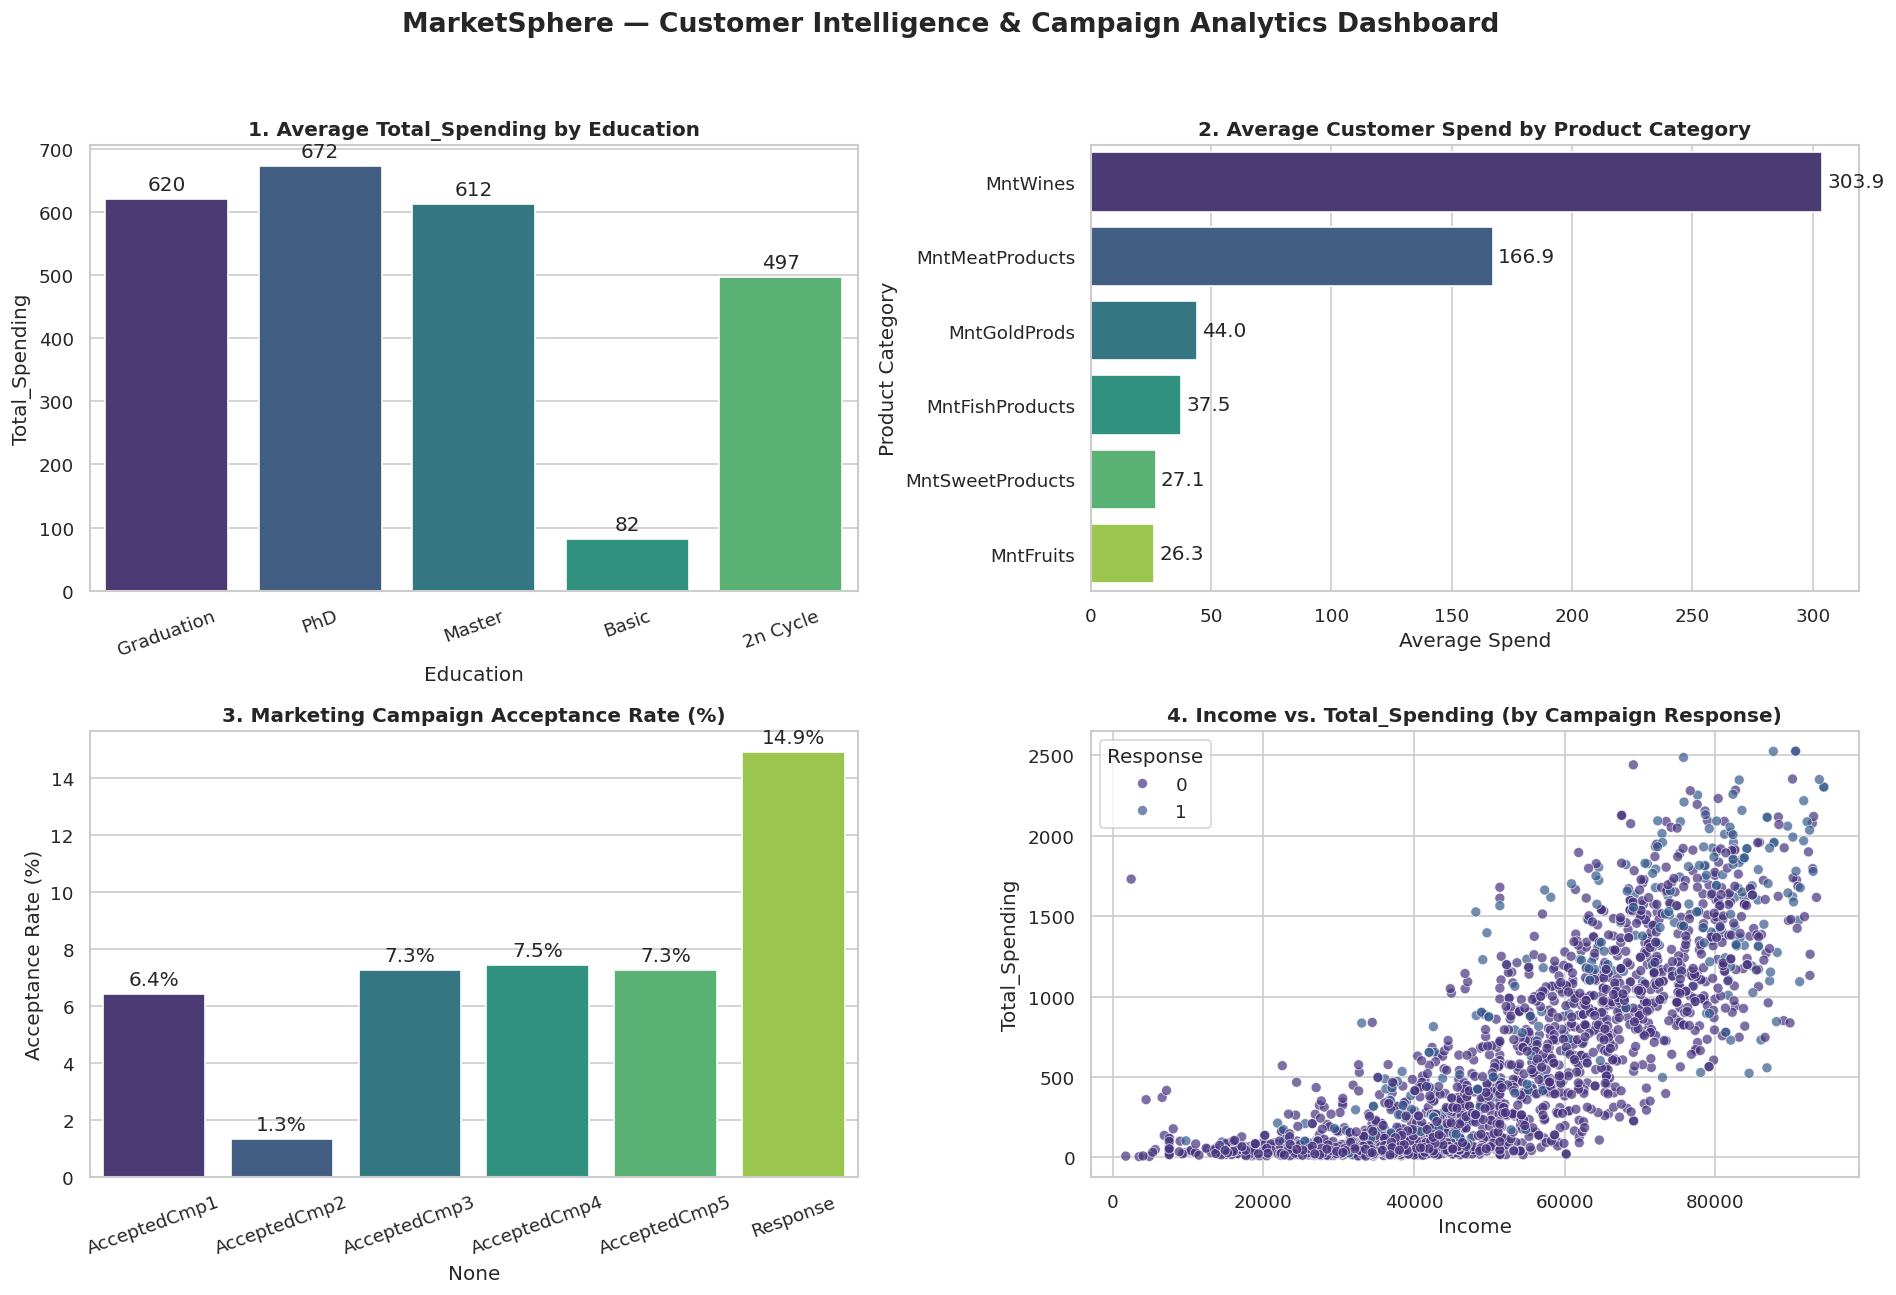


--- CLV MODEL COMPARISON (from reports/clv_model_comparison.csv) ---


,Model,MAE,R2
0,Gradient Boosting Regressor,1318.818145,0.891247



--- CLASSIFICATION MODEL COMPARISON (from reports/classification_model_comparison.csv) ---


,Model,ROC_AUC,Precision,Recall,F1
0,Random Forest Classifier,0.851158,0.447059,0.567164,0.5


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 120

# ==========================================
# 1. LOAD MARKETSPHERE RAW & PROCESSED DATASETS
# ==========================================
raw_df = pd.read_csv("data/raw/marketing_campaign.csv")
clean_df = pd.read_csv("data/processed/marketing_campaign_cleaned.csv")
pred_df = pd.read_csv("results/marketsphere_predictions.csv")

print(f"Raw Dataset Shape:       {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print(f"Processed Dataset Shape: {clean_df.shape[0]:,} rows x {clean_df.shape[1]} columns")
print(f"Predictions Shape:       {pred_df.shape[0]:,} rows x {pred_df.shape[1]} columns\n")

print("--- PREVIEW OF CLEANED MARKETSPHERE DATA ---")
display(clean_df.head())

# ==========================================
# 2. DATA QUALITY & FEATURE INSIGHTS
# ==========================================
print("\n--- MISSING VALUES FIXED (RAW VS CLEANED) ---")
raw_missing = raw_df.isnull().sum()
print(raw_missing[raw_missing > 0])

# Identify spending, campaign, and demographic columns dynamically
spend_cols = [c for c in clean_df.columns if c.startswith("Mnt")]
campaign_cols = [c for c in clean_df.columns if c.startswith("AcceptedCmp") or c == "Response"]

if spend_cols and "Total_Spending" not in clean_df.columns:
    clean_df["Total_Spending"] = clean_df[spend_cols].sum(axis=1)

print("\n--- SUMMARY STATISTICS ---")
display(clean_df.describe().round(2).T[["count", "mean", "std", "50%", "max"]])

# ==========================================
# 3. MARKETSPHERE 4-PANEL VISUAL DASHBOARD
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("MarketSphere — Customer Intelligence & Campaign Analytics Dashboard", fontsize=16, fontweight="bold", y=0.98)

# Panel 1: Total Spending by Education Level (or first categorical column)
cat_col = "Education" if "Education" in clean_df.columns else clean_df.select_dtypes(include="object").columns[0]
spend_target = "Total_Spending" if "Total_Spending" in clean_df.columns else clean_df.select_dtypes(include=np.number).columns[0]

sns.barplot(
    data=clean_df, x=cat_col, y=spend_target,
    estimator=np.mean, errorbar=None, hue=cat_col, legend=False, ax=axes[0, 0]
)
axes[0, 0].set_title(f"1. Average {spend_target} by {cat_col}", fontweight="bold")
axes[0, 0].tick_params(axis="x", rotation=20)
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%.0f", padding=3)

# Panel 2: Product Category Spend Breakdown (if Mnt* columns exist)
if spend_cols:
    cat_means = clean_df[spend_cols].mean().sort_values(ascending=False)
    sns.barplot(x=cat_means.values, y=cat_means.index, hue=cat_means.index, legend=False, ax=axes[0, 1])
    axes[0, 1].set_title("2. Average Customer Spend by Product Category", fontweight="bold")
    axes[0, 1].set_xlabel("Average Spend")
    axes[0, 1].set_ylabel("Product Category")
    for container in axes[0, 1].containers:
        axes[0, 1].bar_label(container, fmt="%.1f", padding=3)
else:
    sns.histplot(data=clean_df, x=spend_target, bins=25, kde=True, color="#2a9d8f", ax=axes[0, 1])
    axes[0, 1].set_title(f"2. {spend_target} Distribution", fontweight="bold")

# Panel 3: Campaign Acceptance Rates Across Waves
if campaign_cols:
    cmp_rates = (clean_df[campaign_cols].mean() * 100).sort_index()
    sns.barplot(x=cmp_rates.index, y=cmp_rates.values, hue=cmp_rates.index, legend=False, ax=axes[1, 0])
    axes[1, 0].set_title("3. Marketing Campaign Acceptance Rate (%)", fontweight="bold")
    axes[1, 0].set_ylabel("Acceptance Rate (%)")
    axes[1, 0].tick_params(axis="x", rotation=20)
    for container in axes[1, 0].containers:
        axes[1, 0].bar_label(container, fmt="%.1f%%", padding=3)

# Panel 4: Income vs. Total Spending Colored by Campaign Response
income_col = "Income" if "Income" in clean_df.columns else clean_df.select_dtypes(include=np.number).columns[1]
resp_col = "Response" if "Response" in clean_df.columns else None

sns.scatterplot(
    data=clean_df[clean_df[income_col] < clean_df[income_col].quantile(0.99)],
    x=income_col, y=spend_target, hue=resp_col, alpha=0.7, ax=axes[1, 1]
)
axes[1, 1].set_title(f"4. {income_col} vs. {spend_target} (by Campaign Response)", fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("marketsphere_module5_dashboard.png", dpi=150)
plt.show()

# ==========================================
# 4. MODEL BENCHMARK SUMMARY FROM YOUR REPO
# ==========================================
print("\n--- CLV MODEL COMPARISON (from reports/clv_model_comparison.csv) ---")
display(pd.read_csv("reports/clv_model_comparison.csv"))

print("\n--- CLASSIFICATION MODEL COMPARISON (from reports/classification_model_comparison.csv) ---")
display(pd.read_csv("reports/classification_model_comparison.csv"))

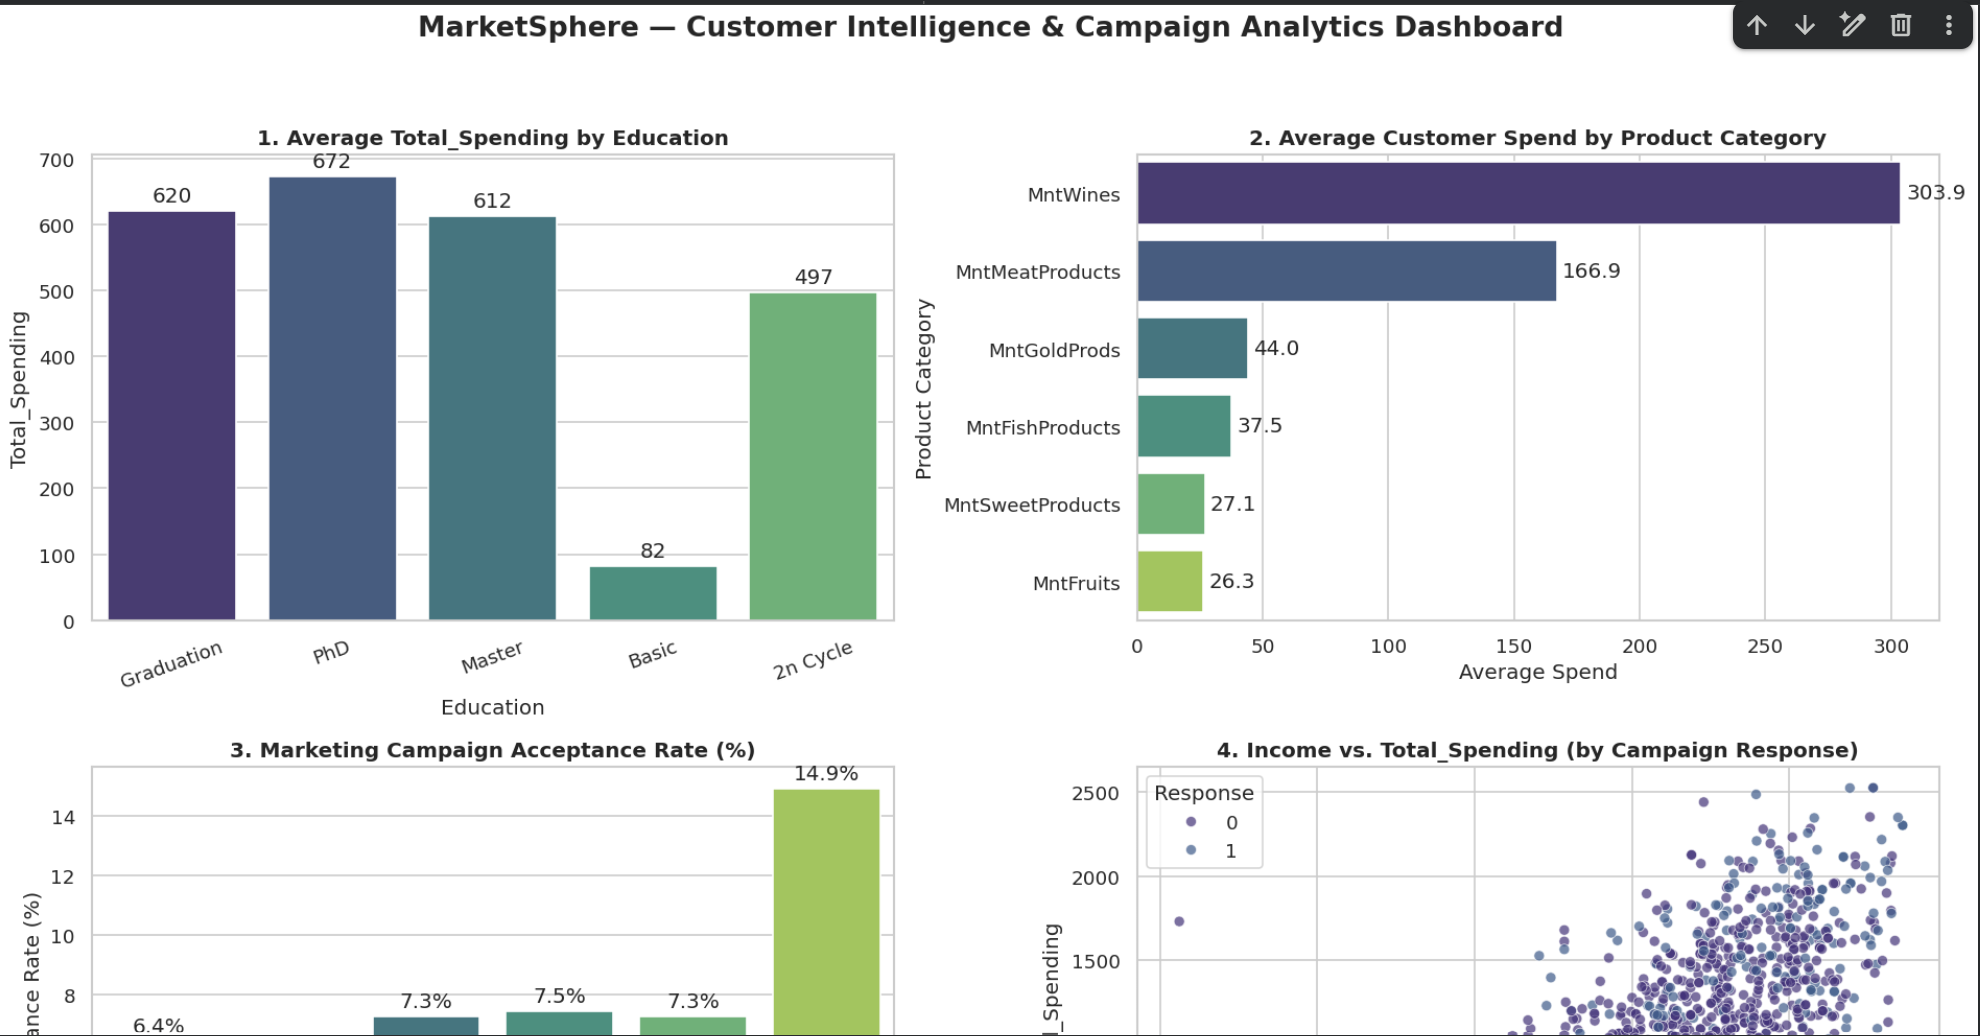

In [9]:
import os

# Re-clone MarketSphere if the Colab runtime reset
if not os.path.exists("/content/MarketSphere"):
    !git clone https://github.com/madhukshara09/MarketSphere.git /content/MarketSphere

%cd /content/MarketSphere

/content/MarketSphere
